# HERMES visual evidence review

Upload this notebook to the **same AutoDL container** and choose **Restart Kernel → Run All**.
Use a CPU session if available. It reads the existing 10 clips under
`/root/autodl-tmp/hermes_short_query_confirmation_v2/videos`. No downloads or
model inference are needed.

It renders the exact pre-query frame slots for the **12 questions** where exactly one
of the primary methods was correct. The recent sheet shows the four frames that
compact recent-four received. The older sheets show additional frames used during
all-history encoding. The frame IDs and timestamps come from the saved run, and the
runner checks each clip hash before decoding.

Review the sheets **before** consulting the separate outcome key. Record where
decisive evidence is visible and which sample indices support your judgement.
Use **uncertain** for ambiguous or motion-dependent cases. Thumbnails can hide
small text. Use the original-frame helper to check it before assigning
**not_visible**. This is a diagnostic review of disagreements, so it cannot
estimate how common a mechanism is in the benchmark.


In [1]:
from pathlib import Path
import csv, hashlib, json, os, shutil, subprocess

BASE = Path('/root/autodl-tmp')
MEDIA = BASE / 'hermes_short_query_confirmation_v2/videos'
PYTHON = BASE / 'hermes_causal_pilot/venv/bin/python'
WORK = BASE / 'hermes_confirmation_visual_review'
VALIDATE_ONLY = os.environ.get('HERMES_VISUAL_REVIEW_VALIDATE_ONLY') == '1'
if not VALIDATE_ONLY:
    from IPython.display import FileLink, Image, Markdown, display


## 1. Render the frozen frames
The embedded data pins the clip hashes and input frame slots.


In [2]:
RUNNER_SOURCE = '"""Render the exact saved pre-query frame slots from the verified local clips."""\nimport argparse\nimport csv\nimport hashlib\nimport html\nimport json\nimport re\nfrom collections import defaultdict\nfrom pathlib import Path\nfrom zipfile import ZIP_DEFLATED, ZipFile\n\nNOTES_FIELDS = (\n    "case_id", "reviewer", "support_region", "supporting_sample_indices", "reviewer_choice",\n    "confidence", "ambiguity_or_motion", "notes",\n)\nREGIONS = ("recent_only", "older_only", "both_independently", "needs_both", "not_visible", "uncertain")\n\n\ndef sha(path):\n    h = hashlib.sha256()\n    with path.open("rb") as handle:\n        for chunk in iter(lambda: handle.read(1024 * 1024), b""):\n            h.update(chunk)\n    return h.hexdigest()\n\n\ndef write_csv(path, fields, rows):\n    with path.open("w", encoding="utf-8", newline="") as handle:\n        writer = csv.DictWriter(handle, fieldnames=fields)\n        writer.writeheader()\n        writer.writerows(rows)\n\n\ndef validated_frames(case):\n    frames = case["frames"]\n    if not re.fullmatch(r"sample_\\d+_q\\d+", case["case_id"]):\n        raise ValueError("Unexpected case ID")\n    if not 1 <= len(frames) <= 20 or [f["sampled_index"] for f in frames] != sorted({f["sampled_index"] for f in frames}):\n        raise ValueError(f"Unexpected sample order: {case[\'case_id\']}")\n    for i, f in enumerate(frames):\n        expected = "recent" if i >= len(frames) - 4 else "older"\n        if (f["region"] != expected or f["source_frame"] < 0\n                or not 0 <= f["start_s"] <= case["query_time_s"] + 1e-6):\n            raise ValueError(f"Invalid or post-query frame in {case[\'case_id\']}")\n    return frames\n\n\ndef reader_for(case, media_root):\n    from decord import VideoReader, cpu\n\n    path = media_root / f"sample_{case[\'sample_id\']}_real.mp4"\n    if not path.is_file():\n        raise FileNotFoundError(f"Missing original clip: {path}")\n    if sha(path) != case["video_sha256"]:\n        raise ValueError(f"Clip checksum differs from the confirmation run: {path.name}")\n    return VideoReader(str(path), ctx=cpu(0), num_threads=1)\n\n\ndef verify_timestamps(reader, frames):\n    origin = float(reader.get_frame_timestamp(0)[0])\n    indices = [f["source_frame"] for f in frames]\n    if max(indices) >= len(reader):\n        raise ValueError("Saved frame index outside decoded clip")\n    times = reader.get_frame_timestamp(indices).tolist()\n    if any(abs(t[0] - origin - f["start_s"]) > 0.001 for t, f in zip(times, frames, strict=True)):\n        raise ValueError("Decoder timestamps differ from the audited sampling record")\n\n\ndef render_sheet(reader, frames, title, columns, width, height, output):\n    from PIL import Image, ImageDraw, ImageFont\n\n    margin, caption = 10, 27\n    vertical = (len(frames) + columns - 1) // columns\n    canvas = Image.new("RGB", (columns*(width + margin)+margin, 48+vertical*(height+caption+margin)), "#fafafa")\n    draw = ImageDraw.Draw(canvas)\n    try:\n        font = ImageFont.truetype("/usr/share/fonts/truetype/dejavu/DejaVuSans.ttf", 15)\n        title_font = ImageFont.truetype("/usr/share/fonts/truetype/dejavu/DejaVuSans-Bold.ttf", 18)\n    except OSError:\n        font = title_font = ImageFont.load_default()\n    draw.text((margin, 12), title, anchor="lt", fill="#182334", font=title_font)\n    for i, frame in enumerate(frames):\n        x = margin + (i % columns)*(width+margin)\n        y = 42 + (i // columns)*(height+caption+margin)\n        image = Image.fromarray(reader[frame["source_frame"]].asnumpy())\n        image.thumbnail((width, height), Image.Resampling.LANCZOS)\n        draw.rectangle((x, y, x+width, y+height), fill="#222222")\n        canvas.paste(image, (x+(width-image.width)//2, y+(height-image.height)//2))\n        text = f"Sample {frame[\'sampled_index\']}    {frame[\'start_s\']:.2f} s"\n        draw.text((x, y+height+5), text, anchor="lt", fill="#182334", font=font)\n    canvas.save(output, quality=92)\n\n\ndef render(case, reader, output):\n    frames = validated_frames(case)\n    verify_timestamps(reader, frames)\n    folder = output / "sheets" / case["case_id"]\n    folder.mkdir(parents=True, exist_ok=True)\n    recent = [f for f in frames if f["region"] == "recent"]\n    older = [f for f in frames if f["region"] == "older"]\n    title = f"{case[\'case_id\']}  |  Question at {case[\'query_time_s\']:.2f} s"\n    render_sheet(reader, recent, title + "  |  Recent frames", 2, 560, 315, folder/"recent.jpg")\n    for i in range(0, len(older), 8):\n        render_sheet(reader, older[i:i+8], title + f"  |  Older frames, page {i//8+1}",\n                     4, 295, 166, folder/f"older_{i//8+1}.jpg")\n\n\ndef blind_index(cases, output):\n    lines = [\n        \'<!doctype html><meta charset="utf-8"><title>HERMES visual evidence review</title>\',\n        "<h1>HERMES visual evidence review</h1>",\n        "<p>Review the question and frames before consulting the separate answer key. "\n        "Sample numbers refer to the original 0.5 FPS grid.</p>",\n    ]\n    for case in cases:\n        key = case["case_id"]\n        folder = output / "sheets" / key\n        lines.extend([f\'<h2 id="{key}">{key} · {case["query_time_s"]:.2f} s</h2>\',\n                      f"<p>{html.escape(case[\'question\'])}</p><ol type=\'A\'>"])\n        lines.extend(f"<li>{html.escape(choice)}</li>" for choice in case["choices"])\n        lines.append("</ol>")\n        for file in [folder/"recent.jpg", *sorted(folder.glob("older_*.jpg"))]:\n            path = file.relative_to(output).as_posix()\n            lines.append(f\'<img src="{path}" alt="{file.stem}" style="display:block;max-width:100%;margin:12px 0">\')\n    (output / "index.html").write_text("\\n".join(lines) + "\\n", encoding="utf-8")\n\n\ndef generate(reference, media, output):\n    cases = reference["cases"]\n    outcome = reference["outcomes"]\n    if len(cases) != 12 or {c["case_id"] for c in cases} != {r["case_id"] for r in outcome}:\n        raise ValueError("Unexpected discordance list")\n    output.mkdir(parents=True, exist_ok=True)\n    by_clip = defaultdict(list)\n    for case in cases:\n        validated_frames(case)\n        by_clip[case["sample_id"]].append(case)\n    for sid, group in by_clip.items():\n        if len({c["video_sha256"] for c in group}) != 1:\n            raise ValueError(f"Conflicting media checksums for sample {sid}")\n        reader = reader_for(group[0], media)\n        for case in group:\n            render(case, reader, output)\n            print(f"VISUAL_CASE_READY {case[\'case_id\']}", flush=True)\n        del reader\n    blind_index(cases, output)\n    # Save existing judgements across notebook reruns.\n    notes = output / "review_notes.csv"\n    if not notes.exists():\n        write_csv(notes, NOTES_FIELDS, [{"case_id": c["case_id"]} for c in cases])\n    else:\n        with notes.open(encoding="utf-8-sig", newline="") as handle:\n            saved = csv.DictReader(handle)\n            if tuple(saved.fieldnames or ()) != NOTES_FIELDS or [r["case_id"] for r in saved] != [c["case_id"] for c in cases]:\n                raise ValueError("Existing review notes do not match the frozen cases")\n    key = output / "after_review" / "outcome_key.csv"\n    key.parent.mkdir(exist_ok=True)\n    write_csv(key, tuple(outcome[0]), outcome)\n    write_csv(output / "frame_slots.csv", ("case_id", "sampled_index", "source_frame", "start_s", "region"), [\n        dict(case_id=c["case_id"], **f) for c in cases for f in c["frames"]\n    ])\n    (output / "review_reference.json").write_text(json.dumps(dict(archive_sha256=reference["archive_sha256"],\n        cases=cases, support_regions=REGIONS), ensure_ascii=False, indent=2) + "\\n", encoding="utf-8")\n\n\ndef inspect_frame(reference, media, output, case_id, sampled_index):\n    from PIL import Image\n\n    case = next((c for c in reference["cases"] if c["case_id"] == case_id), None)\n    if case is None:\n        raise ValueError("Unknown case ID")\n    frame = next((f for f in validated_frames(case) if f["sampled_index"] == sampled_index), None)\n    if frame is None:\n        raise ValueError("Requested sample was outside the model input")\n    reader = reader_for(case, media)\n    verify_timestamps(reader, [frame])\n    folder = output / "originals"\n    folder.mkdir(parents=True, exist_ok=True)\n    path = folder / f"{case_id}_sample_{sampled_index:04d}.png"\n    Image.fromarray(reader[frame["source_frame"]].asnumpy()).save(path)\n    print(path)\n\n\ndef package(output, dest):\n    files = [output/n for n in ("index.html", "review_notes.csv", "frame_slots.csv", "review_reference.json",\n                                  "after_review/outcome_key.csv")]\n    files += sorted((output / "sheets").glob("*/*.jpg"))\n    files += sorted((output / "originals").glob("*.png"))\n    temp = dest.with_suffix(".tmp")\n    with ZipFile(temp, "w", compression=ZIP_DEFLATED) as zipped:\n        for path in files:\n            zipped.write(path, path.relative_to(output).as_posix())\n    temp.replace(dest)\n    print(f"VISUAL_REVIEW_ZIP {dest} SHA256={sha(dest)}", flush=True)\n\n\ndef main():\n    parser = argparse.ArgumentParser(description=__doc__)\n    for n in ("reference", "media", "output"):\n        parser.add_argument("--"+n, type=Path, required=True)\n    parser.add_argument("--inspect", nargs=2, metavar=("CASE", "SAMPLE"))\n    parser.add_argument("--zip", type=Path)\n    args = parser.parse_args()\n    reference = json.loads(args.reference.read_text(encoding="utf-8"))\n    if args.inspect:\n        inspect_frame(reference, args.media, args.output, args.inspect[0], int(args.inspect[1]))\n    elif args.zip:\n        package(args.output, args.zip)\n    else:\n        generate(reference, args.media, args.output)\n\n\nif __name__ == "__main__":\n    main()\n'
REFERENCE_JSON = '{"archive_sha256":"291114a32391bbb039e176355688b4b4af269f35ad7a129a73205c73d05575e3","cases":[{"case_id":"sample_109_q3","choices":["1.200V.","1.500V.","1.250V.","1.400V."],"frames":[{"region":"older","sampled_index":281,"source_frame":33686,"start_s":561.9948120117188},{"region":"older","sampled_index":282,"source_frame":33806,"start_s":563.996826171875},{"region":"older","sampled_index":283,"source_frame":33926,"start_s":565.998779296875},{"region":"older","sampled_index":284,"source_frame":34045,"start_s":567.9840698242188},{"region":"older","sampled_index":285,"source_frame":34165,"start_s":569.986083984375},{"region":"older","sampled_index":286,"source_frame":34285,"start_s":571.988037109375},{"region":"older","sampled_index":287,"source_frame":34405,"start_s":573.9900512695312},{"region":"older","sampled_index":288,"source_frame":34525,"start_s":575.9920654296875},{"region":"older","sampled_index":289,"source_frame":34645,"start_s":577.9940795898438},{"region":"older","sampled_index":290,"source_frame":34765,"start_s":579.99609375},{"region":"older","sampled_index":291,"source_frame":34885,"start_s":581.998046875},{"region":"older","sampled_index":292,"source_frame":35004,"start_s":583.9833984375},{"region":"older","sampled_index":293,"source_frame":35124,"start_s":585.9854125976562},{"region":"older","sampled_index":294,"source_frame":35244,"start_s":587.9874267578125},{"region":"older","sampled_index":295,"source_frame":35364,"start_s":589.9893798828125},{"region":"older","sampled_index":296,"source_frame":35484,"start_s":591.9913940429688},{"region":"recent","sampled_index":297,"source_frame":35604,"start_s":593.993408203125},{"region":"recent","sampled_index":298,"source_frame":35724,"start_s":595.9954223632812},{"region":"recent","sampled_index":299,"source_frame":35844,"start_s":597.9973754882812},{"region":"recent","sampled_index":300,"source_frame":35964,"start_s":599.9993896484375}],"query_time_s":601.0,"question":"What value was set for the \\"GFX Voltage\\" just now?","sample_id":109,"video_sha256":"a8414aae79fb3e4918f75a9649d983f68ad695bdfc36c7caeefef219105ec9c5"},{"case_id":"sample_112_q3","choices":["101 fps.","135 fps.","91 fps.","87 fps."],"frames":[{"region":"older","sampled_index":260,"source_frame":31168,"start_s":519.9861450195312},{"region":"older","sampled_index":261,"source_frame":31288,"start_s":521.9881591796875},{"region":"older","sampled_index":262,"source_frame":31408,"start_s":523.9901123046875},{"region":"older","sampled_index":263,"source_frame":31528,"start_s":525.9921264648438},{"region":"older","sampled_index":264,"source_frame":31648,"start_s":527.994140625},{"region":"older","sampled_index":265,"source_frame":31768,"start_s":529.9961547851562},{"region":"older","sampled_index":266,"source_frame":31888,"start_s":531.9981079101562},{"region":"older","sampled_index":267,"source_frame":32007,"start_s":533.9834594726562},{"region":"older","sampled_index":268,"source_frame":32127,"start_s":535.9854736328125},{"region":"older","sampled_index":269,"source_frame":32247,"start_s":537.9874877929688},{"region":"older","sampled_index":270,"source_frame":32367,"start_s":539.9894409179688},{"region":"older","sampled_index":271,"source_frame":32487,"start_s":541.991455078125},{"region":"older","sampled_index":272,"source_frame":32607,"start_s":543.9934692382812},{"region":"older","sampled_index":273,"source_frame":32727,"start_s":545.9954833984375},{"region":"older","sampled_index":274,"source_frame":32847,"start_s":547.9974365234375},{"region":"older","sampled_index":275,"source_frame":32967,"start_s":549.9994506835938},{"region":"recent","sampled_index":276,"source_frame":33086,"start_s":551.9847412109375},{"region":"recent","sampled_index":277,"source_frame":33206,"start_s":553.9867553710938},{"region":"recent","sampled_index":278,"source_frame":33326,"start_s":555.98876953125},{"region":"recent","sampled_index":279,"source_frame":33446,"start_s":557.9907836914062}],"query_time_s":560.0,"question":"What frame rate does the RTX 3080 Ti with Intel i9 12900K and 32G DDR5 4800 achieve for \\"God of War 4\\" at 4K+DLSS right now?","sample_id":112,"video_sha256":"614aee17550e376de17c6491d70af9ea2e854b4a2cb3fafea7ae8f4da8ffc4f1"},{"case_id":"sample_118_q1","choices":["Noctua.","Cooler Master.","Corsair.","Be Quiet!."],"frames":[{"region":"older","sampled_index":64,"source_frame":7680,"start_s":128.0},{"region":"older","sampled_index":65,"source_frame":7800,"start_s":130.0},{"region":"older","sampled_index":66,"source_frame":7920,"start_s":132.0},{"region":"older","sampled_index":67,"source_frame":8040,"start_s":134.0},{"region":"older","sampled_index":68,"source_frame":8160,"start_s":136.0},{"region":"older","sampled_index":69,"source_frame":8280,"start_s":138.0},{"region":"older","sampled_index":70,"source_frame":8400,"start_s":140.0},{"region":"older","sampled_index":71,"source_frame":8520,"start_s":142.0},{"region":"older","sampled_index":72,"source_frame":8640,"start_s":144.0},{"region":"older","sampled_index":73,"source_frame":8760,"start_s":146.0},{"region":"older","sampled_index":74,"source_frame":8880,"start_s":148.0},{"region":"older","sampled_index":75,"source_frame":9000,"start_s":150.0},{"region":"older","sampled_index":76,"source_frame":9120,"start_s":152.0},{"region":"older","sampled_index":77,"source_frame":9240,"start_s":154.0},{"region":"older","sampled_index":78,"source_frame":9360,"start_s":156.0},{"region":"older","sampled_index":79,"source_frame":9480,"start_s":158.0},{"region":"recent","sampled_index":80,"source_frame":9600,"start_s":160.0},{"region":"recent","sampled_index":81,"source_frame":9720,"start_s":162.0},{"region":"recent","sampled_index":82,"source_frame":9840,"start_s":164.0},{"region":"recent","sampled_index":83,"source_frame":9960,"start_s":166.0}],"query_time_s":167.0,"question":"What brand of heatsink is being installed onto the motherboard\'s CPU right now?","sample_id":118,"video_sha256":"24f40b416dadabc6161192b99f501d3543a561b7061df8a01ac0fbc24ca9d437"},{"case_id":"sample_121_q3","choices":["2314.","2691.","1308.","3972."],"frames":[{"region":"older","sampled_index":260,"source_frame":31200,"start_s":520.0},{"region":"older","sampled_index":261,"source_frame":31320,"start_s":522.0},{"region":"older","sampled_index":262,"source_frame":31440,"start_s":524.0},{"region":"older","sampled_index":263,"source_frame":31560,"start_s":526.0},{"region":"older","sampled_index":264,"source_frame":31680,"start_s":528.0},{"region":"older","sampled_index":265,"source_frame":31800,"start_s":530.0},{"region":"older","sampled_index":266,"source_frame":31920,"start_s":532.0},{"region":"older","sampled_index":267,"source_frame":32040,"start_s":534.0},{"region":"older","sampled_index":268,"source_frame":32160,"start_s":536.0},{"region":"older","sampled_index":269,"source_frame":32280,"start_s":538.0},{"region":"older","sampled_index":270,"source_frame":32400,"start_s":540.0},{"region":"older","sampled_index":271,"source_frame":32520,"start_s":542.0},{"region":"older","sampled_index":272,"source_frame":32640,"start_s":544.0},{"region":"older","sampled_index":273,"source_frame":32760,"start_s":546.0},{"region":"older","sampled_index":274,"source_frame":32880,"start_s":548.0},{"region":"older","sampled_index":275,"source_frame":33000,"start_s":550.0},{"region":"recent","sampled_index":276,"source_frame":33120,"start_s":552.0},{"region":"recent","sampled_index":277,"source_frame":33240,"start_s":554.0},{"region":"recent","sampled_index":278,"source_frame":33360,"start_s":556.0},{"region":"recent","sampled_index":279,"source_frame":33480,"start_s":558.0}],"query_time_s":559.0,"question":"What is the V-Ray 5 benchmark score for the RTX 3080 right now?","sample_id":121,"video_sha256":"dcb137c361d7b97e4842a7dcb101604980c4848c18c50c2a0e3670978f54eebf"},{"case_id":"sample_121_q4","choices":["Radeon RX 590.","GeForce GTX 1080.","GeForce RTX 4080.","Radeon RX 6700."],"frames":[{"region":"older","sampled_index":333,"source_frame":39960,"start_s":666.0},{"region":"older","sampled_index":334,"source_frame":40080,"start_s":668.0},{"region":"older","sampled_index":335,"source_frame":40200,"start_s":670.0},{"region":"older","sampled_index":336,"source_frame":40320,"start_s":672.0},{"region":"older","sampled_index":337,"source_frame":40440,"start_s":674.0},{"region":"older","sampled_index":338,"source_frame":40560,"start_s":676.0},{"region":"older","sampled_index":339,"source_frame":40680,"start_s":678.0},{"region":"older","sampled_index":340,"source_frame":40800,"start_s":680.0},{"region":"older","sampled_index":341,"source_frame":40920,"start_s":682.0},{"region":"older","sampled_index":342,"source_frame":41040,"start_s":684.0},{"region":"older","sampled_index":343,"source_frame":41160,"start_s":686.0},{"region":"older","sampled_index":344,"source_frame":41280,"start_s":688.0},{"region":"older","sampled_index":345,"source_frame":41400,"start_s":690.0},{"region":"older","sampled_index":346,"source_frame":41520,"start_s":692.0},{"region":"older","sampled_index":347,"source_frame":41640,"start_s":694.0},{"region":"older","sampled_index":348,"source_frame":41760,"start_s":696.0},{"region":"recent","sampled_index":349,"source_frame":41880,"start_s":698.0},{"region":"recent","sampled_index":350,"source_frame":42000,"start_s":700.0},{"region":"recent","sampled_index":351,"source_frame":42120,"start_s":702.0},{"region":"recent","sampled_index":352,"source_frame":42240,"start_s":704.0}],"query_time_s":705.0,"question":"What brand and model of the graphics card box is visible on the man\'s hand right now?","sample_id":121,"video_sha256":"dcb137c361d7b97e4842a7dcb101604980c4848c18c50c2a0e3670978f54eebf"},{"case_id":"sample_131_q3","choices":["Adding red paint.","Adding green paint.","Adding blue paint.","Adding yellow paint."],"frames":[{"region":"older","sampled_index":255,"source_frame":12240,"start_s":510.0},{"region":"older","sampled_index":256,"source_frame":12288,"start_s":512.0},{"region":"older","sampled_index":257,"source_frame":12336,"start_s":514.0},{"region":"older","sampled_index":258,"source_frame":12384,"start_s":516.0},{"region":"older","sampled_index":259,"source_frame":12432,"start_s":518.0},{"region":"older","sampled_index":260,"source_frame":12480,"start_s":520.0},{"region":"older","sampled_index":261,"source_frame":12528,"start_s":522.0},{"region":"older","sampled_index":262,"source_frame":12576,"start_s":524.0},{"region":"older","sampled_index":263,"source_frame":12624,"start_s":526.0},{"region":"older","sampled_index":264,"source_frame":12672,"start_s":528.0},{"region":"older","sampled_index":265,"source_frame":12720,"start_s":530.0},{"region":"older","sampled_index":266,"source_frame":12768,"start_s":532.0},{"region":"older","sampled_index":267,"source_frame":12816,"start_s":534.0},{"region":"older","sampled_index":268,"source_frame":12864,"start_s":536.0},{"region":"older","sampled_index":269,"source_frame":12912,"start_s":538.0},{"region":"older","sampled_index":270,"source_frame":12960,"start_s":540.0},{"region":"recent","sampled_index":271,"source_frame":13008,"start_s":542.0},{"region":"recent","sampled_index":272,"source_frame":13056,"start_s":544.0},{"region":"recent","sampled_index":273,"source_frame":13104,"start_s":546.0},{"region":"recent","sampled_index":274,"source_frame":13152,"start_s":548.0}],"query_time_s":549.0,"question":"What action is the painter performing at the upper left corner of the painting?","sample_id":131,"video_sha256":"0c99578b431ca6abf4ad2ea122d3237f16395df4eb46cb5f7c67103f609be9f2"},{"case_id":"sample_133_q2","choices":["On an easel.","On the floor.","On a table.","On a wall."],"frames":[{"region":"older","sampled_index":190,"source_frame":9120,"start_s":380.0},{"region":"older","sampled_index":191,"source_frame":9168,"start_s":382.0},{"region":"older","sampled_index":192,"source_frame":9216,"start_s":384.0},{"region":"older","sampled_index":193,"source_frame":9264,"start_s":386.0},{"region":"older","sampled_index":194,"source_frame":9312,"start_s":388.0},{"region":"older","sampled_index":195,"source_frame":9360,"start_s":390.0},{"region":"older","sampled_index":196,"source_frame":9408,"start_s":392.0},{"region":"older","sampled_index":197,"source_frame":9456,"start_s":394.0},{"region":"older","sampled_index":198,"source_frame":9504,"start_s":396.0},{"region":"older","sampled_index":199,"source_frame":9552,"start_s":398.0},{"region":"older","sampled_index":200,"source_frame":9600,"start_s":400.0},{"region":"older","sampled_index":201,"source_frame":9648,"start_s":402.0},{"region":"older","sampled_index":202,"source_frame":9696,"start_s":404.0},{"region":"older","sampled_index":203,"source_frame":9744,"start_s":406.0},{"region":"older","sampled_index":204,"source_frame":9792,"start_s":408.0},{"region":"older","sampled_index":205,"source_frame":9840,"start_s":410.0},{"region":"recent","sampled_index":206,"source_frame":9888,"start_s":412.0},{"region":"recent","sampled_index":207,"source_frame":9936,"start_s":414.0},{"region":"recent","sampled_index":208,"source_frame":9984,"start_s":416.0},{"region":"recent","sampled_index":209,"source_frame":10032,"start_s":418.0}],"query_time_s":420.0,"question":"Where is the painting set while the artist works on it?","sample_id":133,"video_sha256":"f874abc93aa61893f80d6d84980a705f1f6f6f9156cdac5d31362268d5be71f6"},{"case_id":"sample_133_q3","choices":["A rough sketch of a landscape.","Add background color to the portrait.","An abstract painting with vibrant colors.","A still life painting of fruits and flowers."],"frames":[{"region":"older","sampled_index":190,"source_frame":9120,"start_s":380.0},{"region":"older","sampled_index":191,"source_frame":9168,"start_s":382.0},{"region":"older","sampled_index":192,"source_frame":9216,"start_s":384.0},{"region":"older","sampled_index":193,"source_frame":9264,"start_s":386.0},{"region":"older","sampled_index":194,"source_frame":9312,"start_s":388.0},{"region":"older","sampled_index":195,"source_frame":9360,"start_s":390.0},{"region":"older","sampled_index":196,"source_frame":9408,"start_s":392.0},{"region":"older","sampled_index":197,"source_frame":9456,"start_s":394.0},{"region":"older","sampled_index":198,"source_frame":9504,"start_s":396.0},{"region":"older","sampled_index":199,"source_frame":9552,"start_s":398.0},{"region":"older","sampled_index":200,"source_frame":9600,"start_s":400.0},{"region":"older","sampled_index":201,"source_frame":9648,"start_s":402.0},{"region":"older","sampled_index":202,"source_frame":9696,"start_s":404.0},{"region":"older","sampled_index":203,"source_frame":9744,"start_s":406.0},{"region":"older","sampled_index":204,"source_frame":9792,"start_s":408.0},{"region":"older","sampled_index":205,"source_frame":9840,"start_s":410.0},{"region":"recent","sampled_index":206,"source_frame":9888,"start_s":412.0},{"region":"recent","sampled_index":207,"source_frame":9936,"start_s":414.0},{"region":"recent","sampled_index":208,"source_frame":9984,"start_s":416.0},{"region":"recent","sampled_index":209,"source_frame":10032,"start_s":418.0}],"query_time_s":420.0,"question":"Which of the following best summarizes the painting process shown just now?","sample_id":133,"video_sha256":"f874abc93aa61893f80d6d84980a705f1f6f6f9156cdac5d31362268d5be71f6"},{"case_id":"sample_140_q2","choices":["Mixing colors on the palette.","Framing the finished painting.","Applying fine details to the grass lawn.","Cleaning the brush with water."],"frames":[{"region":"older","sampled_index":50,"source_frame":3000,"start_s":100.0},{"region":"older","sampled_index":51,"source_frame":3060,"start_s":102.0},{"region":"older","sampled_index":52,"source_frame":3120,"start_s":104.0},{"region":"older","sampled_index":53,"source_frame":3180,"start_s":106.0},{"region":"older","sampled_index":54,"source_frame":3240,"start_s":108.0},{"region":"older","sampled_index":55,"source_frame":3300,"start_s":110.0},{"region":"older","sampled_index":56,"source_frame":3360,"start_s":112.0},{"region":"older","sampled_index":57,"source_frame":3420,"start_s":114.0},{"region":"older","sampled_index":58,"source_frame":3480,"start_s":116.0},{"region":"older","sampled_index":59,"source_frame":3540,"start_s":118.0},{"region":"older","sampled_index":60,"source_frame":3600,"start_s":120.0},{"region":"older","sampled_index":61,"source_frame":3660,"start_s":122.0},{"region":"older","sampled_index":62,"source_frame":3720,"start_s":124.0},{"region":"older","sampled_index":63,"source_frame":3780,"start_s":126.0},{"region":"older","sampled_index":64,"source_frame":3840,"start_s":128.0},{"region":"older","sampled_index":65,"source_frame":3900,"start_s":130.0},{"region":"recent","sampled_index":66,"source_frame":3960,"start_s":132.0},{"region":"recent","sampled_index":67,"source_frame":4020,"start_s":134.0},{"region":"recent","sampled_index":68,"source_frame":4080,"start_s":136.0},{"region":"recent","sampled_index":69,"source_frame":4140,"start_s":138.0}],"query_time_s":139.0,"question":"What action is the artist performing right now?","sample_id":140,"video_sha256":"54e59dbfaf3b76511d1c70e7af3b3c810351c2f36a3c0e57f107cc16b31058ba"},{"case_id":"sample_146_q2","choices":["Dumbbells.","A kettlebell.","A barbell.","A medicine ball."],"frames":[{"region":"older","sampled_index":70,"source_frame":8391,"start_s":139.98985290527344},{"region":"older","sampled_index":71,"source_frame":8511,"start_s":141.99185180664062},{"region":"older","sampled_index":72,"source_frame":8631,"start_s":143.9938507080078},{"region":"older","sampled_index":73,"source_frame":8751,"start_s":145.995849609375},{"region":"older","sampled_index":74,"source_frame":8871,"start_s":147.9978485107422},{"region":"older","sampled_index":75,"source_frame":8991,"start_s":149.99984741210938},{"region":"older","sampled_index":76,"source_frame":9110,"start_s":151.98516845703125},{"region":"older","sampled_index":77,"source_frame":9230,"start_s":153.98716735839844},{"region":"older","sampled_index":78,"source_frame":9350,"start_s":155.98916625976562},{"region":"older","sampled_index":79,"source_frame":9470,"start_s":157.9911651611328},{"region":"older","sampled_index":80,"source_frame":9590,"start_s":159.9931640625},{"region":"older","sampled_index":81,"source_frame":9710,"start_s":161.9951629638672},{"region":"older","sampled_index":82,"source_frame":9830,"start_s":163.99716186523438},{"region":"older","sampled_index":83,"source_frame":9950,"start_s":165.99916076660156},{"region":"older","sampled_index":84,"source_frame":10069,"start_s":167.98448181152344},{"region":"older","sampled_index":85,"source_frame":10189,"start_s":169.98648071289062},{"region":"recent","sampled_index":86,"source_frame":10309,"start_s":171.9884796142578},{"region":"recent","sampled_index":87,"source_frame":10429,"start_s":173.990478515625},{"region":"recent","sampled_index":88,"source_frame":10549,"start_s":175.9924774169922},{"region":"recent","sampled_index":89,"source_frame":10669,"start_s":177.99447631835938}],"query_time_s":180.0,"question":"What is the man holding above his chest right now?","sample_id":146,"video_sha256":"56fea25ecd6141eb7ed69bb4c0accf84cc881d0deb5eeef56c64ed40b9eaeb33"},{"case_id":"sample_53_q0","choices":["Removing the cutting mat from the cutting machine.","Cutting the pink paper on the mat manually.","Decorating the cutting mat with stickers.","Placing the cutting mat into the cutting machine."],"frames":[{"region":"older","sampled_index":0,"source_frame":0,"start_s":0.0},{"region":"older","sampled_index":1,"source_frame":48,"start_s":2.0},{"region":"older","sampled_index":2,"source_frame":96,"start_s":4.0},{"region":"older","sampled_index":3,"source_frame":144,"start_s":6.0},{"region":"older","sampled_index":4,"source_frame":192,"start_s":8.0},{"region":"older","sampled_index":5,"source_frame":240,"start_s":10.0},{"region":"older","sampled_index":6,"source_frame":288,"start_s":12.0},{"region":"recent","sampled_index":7,"source_frame":336,"start_s":14.0},{"region":"recent","sampled_index":8,"source_frame":384,"start_s":16.0},{"region":"recent","sampled_index":9,"source_frame":432,"start_s":18.0},{"region":"recent","sampled_index":10,"source_frame":480,"start_s":20.0}],"query_time_s":21.0,"question":"What is being done with the cutting mat right now?","sample_id":53,"video_sha256":"bb465296d5d7b37faf8fb09d3bce7c92d10cd9e8187b9c0a1b46ebe32a139f52"},{"case_id":"sample_63_q4","choices":["Attaching the name to the transparent hexagonal object.","Adjusting the hexagonal piece with their left hand.","Applying pressure on the green marking with their left hand.","Using a purple tool to press onto the hexagonal piece."],"frames":[{"region":"older","sampled_index":201,"source_frame":9648,"start_s":402.0},{"region":"older","sampled_index":202,"source_frame":9696,"start_s":404.0},{"region":"older","sampled_index":203,"source_frame":9744,"start_s":406.0},{"region":"older","sampled_index":204,"source_frame":9792,"start_s":408.0},{"region":"older","sampled_index":205,"source_frame":9840,"start_s":410.0},{"region":"older","sampled_index":206,"source_frame":9888,"start_s":412.0},{"region":"older","sampled_index":207,"source_frame":9936,"start_s":414.0},{"region":"older","sampled_index":208,"source_frame":9984,"start_s":416.0},{"region":"older","sampled_index":209,"source_frame":10032,"start_s":418.0},{"region":"older","sampled_index":210,"source_frame":10080,"start_s":420.0},{"region":"older","sampled_index":211,"source_frame":10128,"start_s":422.0},{"region":"older","sampled_index":212,"source_frame":10176,"start_s":424.0},{"region":"older","sampled_index":213,"source_frame":10224,"start_s":426.0},{"region":"older","sampled_index":214,"source_frame":10272,"start_s":428.0},{"region":"older","sampled_index":215,"source_frame":10320,"start_s":430.0},{"region":"older","sampled_index":216,"source_frame":10368,"start_s":432.0},{"region":"recent","sampled_index":217,"source_frame":10416,"start_s":434.0},{"region":"recent","sampled_index":218,"source_frame":10464,"start_s":436.0},{"region":"recent","sampled_index":219,"source_frame":10512,"start_s":438.0},{"region":"recent","sampled_index":220,"source_frame":10560,"start_s":440.0}],"query_time_s":442.0,"question":"What is the person doing right now?","sample_id":63,"video_sha256":"d3b9f623354d44b49c306dd532116e28bd5e320687a4514eff314efdd2f089a7"}],"outcomes":[{"all_history_choice":"D","case_id":"sample_109_q3","compact_choice":"C","correct_arm":"all_history","gold_answer":"1.400V.","gold_choice":"D"},{"all_history_choice":"A","case_id":"sample_112_q3","compact_choice":"D","correct_arm":"all_history","gold_answer":"101 fps.","gold_choice":"A"},{"all_history_choice":"A","case_id":"sample_118_q1","compact_choice":"B","correct_arm":"compact_recent4","gold_answer":"Cooler Master.","gold_choice":"B"},{"all_history_choice":"D","case_id":"sample_121_q3","compact_choice":"A","correct_arm":"compact_recent4","gold_answer":"2314.","gold_choice":"A"},{"all_history_choice":"A","case_id":"sample_121_q4","compact_choice":"C","correct_arm":"compact_recent4","gold_answer":"GeForce RTX 4080.","gold_choice":"C"},{"all_history_choice":"A","case_id":"sample_131_q3","compact_choice":"C","correct_arm":"compact_recent4","gold_answer":"Adding blue paint.","gold_choice":"C"},{"all_history_choice":"A","case_id":"sample_133_q2","compact_choice":"C","correct_arm":"compact_recent4","gold_answer":"On a table.","gold_choice":"C"},{"all_history_choice":"B","case_id":"sample_133_q3","compact_choice":"C","correct_arm":"all_history","gold_answer":"Add background color to the portrait.","gold_choice":"B"},{"all_history_choice":"C","case_id":"sample_140_q2","compact_choice":"A","correct_arm":"all_history","gold_answer":"Applying fine details to the grass lawn.","gold_choice":"C"},{"all_history_choice":"A","case_id":"sample_146_q2","compact_choice":"C","correct_arm":"compact_recent4","gold_answer":"A barbell.","gold_choice":"C"},{"all_history_choice":"B","case_id":"sample_53_q0","compact_choice":"D","correct_arm":"compact_recent4","gold_answer":"Placing the cutting mat into the cutting machine.","gold_choice":"D"},{"all_history_choice":"B","case_id":"sample_63_q4","compact_choice":"A","correct_arm":"compact_recent4","gold_answer":"Attaching the name to the transparent hexagonal object.","gold_choice":"A"}]}'
RUNNER_SHA = '06cefac820e93074c221dd307de324bfd6984e3e40eea32beda20b7dff57d81c'
REFERENCE_SHA = '819565b84d7bc60d0da4dc064fc98b4ec4ae1cdfe9bd9481886de441e696bb7f'
assert hashlib.sha256(RUNNER_SOURCE.encode()).hexdigest() == RUNNER_SHA
assert hashlib.sha256(REFERENCE_JSON.encode()).hexdigest() == REFERENCE_SHA
reference = json.loads(REFERENCE_JSON)
cases = {c['case_id']: c for c in reference['cases']}
if not VALIDATE_ONLY:
    if not PYTHON.is_file():
        raise FileNotFoundError(f'Shared experiment Python is missing: {PYTHON}')
    WORK.mkdir(parents=True, exist_ok=True)
    runner, ref = WORK/'visual_review.py', WORK/'reference.json'
    for path, value in ((runner, RUNNER_SOURCE), (ref, REFERENCE_JSON)):
        if path.exists() and path.read_text(encoding='utf-8') != value:
            raise RuntimeError('Review sources changed. Use a different WORK to preserve earlier notes.')
        path.write_text(value, encoding='utf-8')
    command = [str(PYTHON), str(runner), '--reference', str(ref), '--media', str(MEDIA), '--output', str(WORK)]
    with subprocess.Popen(command, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True) as proc:
        for line in proc.stdout:
            print(line, end='', flush=True)
        if proc.wait():
            raise RuntimeError('Visual review preparation failed. See the output above.')
    print(f'Ready: {len(cases)} cases. Review notes: {WORK / "review_notes.csv"}')
else:
    print('VISUAL_REVIEW_VALIDATION_PASS')


VISUAL_CASE_READY sample_109_q3
VISUAL_CASE_READY sample_112_q3
[h264 @ 0x1eeb340] mmco: unref short failure
[h264 @ 0x1eeb340] mmco: unref short failure
VISUAL_CASE_READY sample_118_q1
[h264 @ 0x1eeb340] mmco: unref short failure
[h264 @ 0x1eeb340] mmco: unref short failure
VISUAL_CASE_READY sample_121_q3
VISUAL_CASE_READY sample_121_q4
VISUAL_CASE_READY sample_131_q3
VISUAL_CASE_READY sample_133_q2
VISUAL_CASE_READY sample_133_q3
VISUAL_CASE_READY sample_140_q2
VISUAL_CASE_READY sample_146_q2
VISUAL_CASE_READY sample_53_q0
VISUAL_CASE_READY sample_63_q4
Ready: 12 cases. Review notes: /root/autodl-tmp/hermes_confirmation_visual_review/review_notes.csv


## 2. Examine each question
Call `show_case(case_id)`. For detail, call `show_original(case_id, sampled_index)` using a displayed sample number.


Case IDs: sample_109_q3, sample_112_q3, sample_118_q1, sample_121_q3, sample_121_q4, sample_131_q3, sample_133_q2, sample_133_q3, sample_140_q2, sample_146_q2, sample_53_q0, sample_63_q4


**sample_109_q3 · 601.00 s**

What value was set for the "GFX Voltage" just now?

- A. 1.200V.
- B. 1.500V.
- C. 1.250V.
- D. 1.400V.

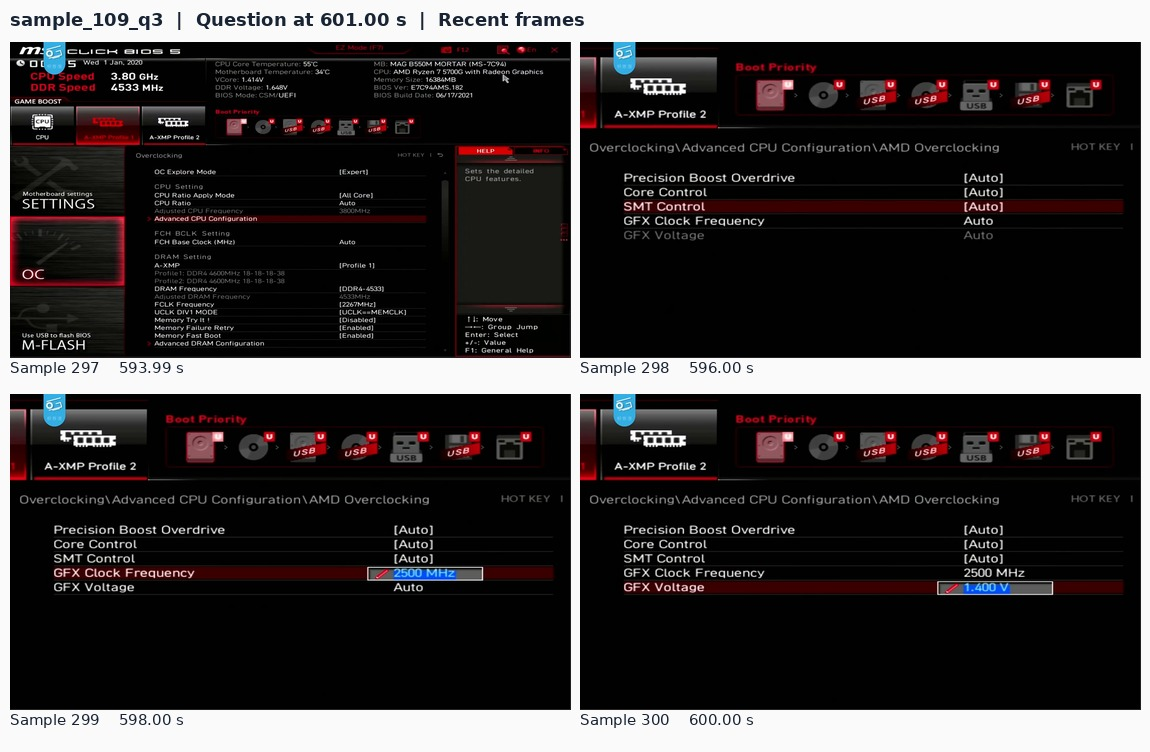

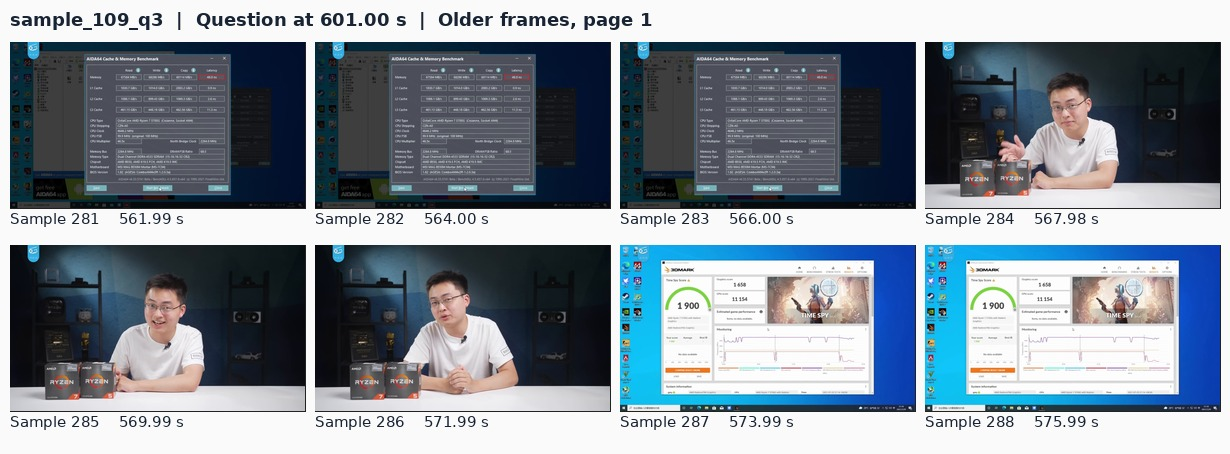

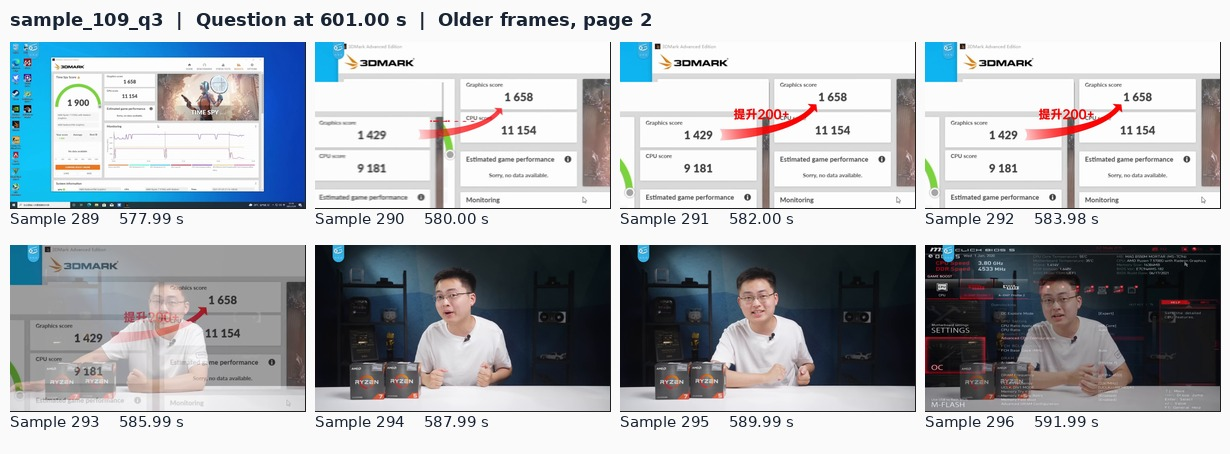

In [3]:
def show_case(case_id):
    case = cases[case_id]
    display(Markdown(f"**{case_id} · {case['query_time_s']:.2f} s**\n\n"
                     + case['question'] + '\n\n'
                     + '\n'.join(f'- {chr(65+i)}. {v}' for i, v in enumerate(case['choices']))))
    folder = WORK / 'sheets' / case_id
    for path in [folder/'recent.jpg', *sorted(folder.glob('older_*.jpg'))]:
        display(Image(filename=str(path)))

def show_original(case_id, sampled_index):
    result = subprocess.run(command + ['--inspect', case_id, str(sampled_index)],
                            check=True, capture_output=True, text=True)
    display(Image(filename=result.stdout.strip().splitlines()[-1]))

if not VALIDATE_ONLY:
    print('Case IDs:', ', '.join(cases))
    show_case(next(iter(cases)))


## 3. Save your observations

Use `record_review` in a new cell or edit `review_notes.csv` directly.
Choose `recent_only`, `older_only`, `both_independently`, `needs_both`,
`not_visible` or `uncertain`. If both windows have support, distinguish
either window being sufficient from needing evidence across both.
Record the sample indices, your best option if you can tell, and any ambiguity
or motion that the sampled stills miss. Leave the separate outcome key for later.


In [4]:
def record_review(case_id, reviewer, support_region, sample_ids=(), choice='', confidence='', notes='', ambiguity_or_motion=''):
    case = cases[case_id]
    sample_ids = tuple(sample_ids)
    permitted = {'recent_only', 'older_only', 'both_independently', 'needs_both', 'not_visible', 'uncertain'}
    frames = {f['sampled_index']: f['region'] for f in case['frames']}
    if support_region not in permitted or not reviewer.strip():
        raise ValueError('Choose a listed support region and enter a reviewer label.')
    if any(i not in frames for i in sample_ids):
        raise ValueError('Use the sample indices shown on this case.')
    required = {'recent_only': {'recent'}, 'older_only': {'older'},
                'both_independently': {'recent', 'older'}, 'needs_both': {'recent', 'older'}}
    if support_region in required and {frames[i] for i in sample_ids} != required[support_region]:
        raise ValueError('Support indices do not match the stated region.')
    if choice and choice not in [chr(65+i) for i in range(len(case['choices']))]:
        raise ValueError('Use an option letter from this question.')
    if confidence not in ('', 'low', 'medium', 'high'):
        raise ValueError('Use low, medium or high.')
    path = WORK/'review_notes.csv'
    with path.open(encoding='utf-8', newline='') as handle:
        reader = csv.DictReader(handle)
        fields, rows = reader.fieldnames, list(reader)
    row = next(r for r in rows if r['case_id'] == case_id)
    row.update(reviewer=reviewer, support_region=support_region,
               supporting_sample_indices=json.dumps(list(sample_ids)), reviewer_choice=choice,
               confidence=confidence, ambiguity_or_motion=ambiguity_or_motion, notes=notes)
    temp = path.with_suffix('.tmp')
    with temp.open('w', encoding='utf-8', newline='') as handle:
        writer = csv.DictWriter(handle, fieldnames=fields)
        writer.writeheader()
        writer.writerows(rows)
    temp.replace(path)
    print(f'Saved {case_id}')

# Use a new cell for each case. Example shape with placeholders:
# record_review(case_id, reviewer, support_region, sample_ids, choice, confidence, notes)


## 4. Download the review package
Rerun this cell after adding notes. Open the extracted `index.html` for all cases. The outcome key is under `after_review/`.


In [5]:
if not VALIDATE_ONLY:
    archive = WORK/'HERMES_confirmation_visual_review.zip'
    subprocess.run(command + ['--zip', str(archive)], check=True)
    link = Path.cwd()/archive.name
    if not link.is_symlink() and link.resolve() != archive.resolve():
        shutil.copy2(archive, link)
    if link.is_symlink():
        raise ValueError('Download copy path is a symlink. Use the ZIP in WORK.')
    display(FileLink(link.name))


VISUAL_REVIEW_ZIP /root/autodl-tmp/hermes_confirmation_visual_review/HERMES_confirmation_visual_review.zip SHA256=1c3facd389dda4d2d92d6064ee193da44422471e37fb08cb6d31f474504bb1d9


/root/autodl-tmp/HERMES-reproduction/HERMES_confirmation_visual_review.zip